# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

O objetivo deste trabalho é explorar e entender melhor as características de duas bases de dados (dados de sensores fotovoltaicos e meteorologicos) a fim de se obter informações necessárias para a previsão de geração de energia.

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares, totalizando 8022697 registros.

**Meteorologico.csv** - referente a dados da estação meteorológica, totalizando 50502 registros.

Com dados coletados entre julho de 2018 e junho de 2019 pertencentes a Smart Campus Facens.


In [1]:
#CÉLULA TCC-01
#Importação de bibliotecas necessárias para execução do trabalho
import pandas as pd
import numpy as np
from datetime import datetime
from collections import Counter

#Gráficos
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MinuteLocator, DayLocator, MonthLocator
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)

from sklearn.preprocessing import MinMaxScaler

In [2]:
#CÉLULA TCC-02
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [3]:
#CÉLULA TCC-03
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-04
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-05
#Identificando todos os datasets referente ao período de quase 1 ano de dados fotovoltaicos
dataSetFotoVoltaico = ['Fotovoltaico_Abr_2019.csv',
'Fotovoltaico_Ago_2018.csv',
'Fotovoltaico_Dez_2018.csv',
'Fotovoltaico_Fev_2019.csv',
'Fotovoltaico_Jan_2019.csv',
'Fotovoltaico_Jul_2018.csv',
'Fotovoltaico_Jun_2019.csv',
'Fotovoltaico_Mai_2019.csv',
'Fotovoltaico_Mar_2019.csv',
'Fotovoltaico_Nov_2018.csv',
'Fotovoltaico_Out_2018.csv',
'Fotovoltaico_Sep_2018.csv']

In [6]:
#CÉLULA TCC-06
#Realizando o carregamento dos dados fotovoltaicos
for idx, data in  enumerate(dataSetFotoVoltaico):
    path = 'F:\Documentos\Data_Science\TCC\Projeto_final\{}'.format(data)
    if idx == 0:
        dfRawFoto = loadDataFile(path, True)
    else:
        dfRawFoto = pd.concat([dfRawFoto, loadDataFile(path, True)])
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8022697 entries, 2019-04-30 23:59:57.940000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           float64
energia_dia      float64
energia_ano      float64
energia_total    float64
potencia         float64
power_led        int64
solarnet_led     int64
solarweb_led     int64
dtypes: float64(5), int64(3)
memory usage: 550.9 MB


In [7]:
#CÉLULA TCC-07
#Selecionando campos
dfRawFoto.drop({
    #'painel',      #Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia', #Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',  #Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia',    #Potência instantânea, é a potência da associação de módulos conectados ao inversor (W);
    'power_led',    #Led ...
    'solarnet_led', #Led ...
    'solarweb_led'  #Led ...
    },axis=1, inplace=True)

In [8]:
#CÉLULA TCC-08
dfRawFoto.isna().sum()

painel         503911
energia_dia    515245
potencia       515245
dtype: int64

In [9]:
#CÉLULA TCC-09
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [10]:
#CÉLULA TCC-10
#Selecionando apenas um inversor (painel)
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [11]:
#CÉLULA TCC-11
#Ordenando o data set pelo index, que representa o campo data
dfRawFoto1 = dfRawFoto1.sort_index()
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-07-01 00:00:06.897,1.0,45990.0,0.0
2018-07-01 00:00:10.697,1.0,45990.0,0.0
2018-07-01 00:00:28.477,1.0,45990.0,0.0
2018-07-01 00:00:48.993,1.0,45990.0,0.0
2018-07-01 00:01:07.387,1.0,45990.0,0.0


In [12]:
#CÉLULA TCC-12
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1881412 entries, 2018-07-01 00:00:06.897000 to 2019-06-19 13:31:31.123000
Data columns (total 3 columns):
painel         float64
energia_dia    float64
potencia       float64
dtypes: float64(3)
memory usage: 57.4 MB


In [13]:
#CÉLULA TCC-13
#Criandno uma coluna nova para conter apenas a energia gerada
dfRawFoto1['energia'] = np.where(dfRawFoto1['potencia'] > 0, dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1), 0)

In [14]:
#CÉLULA TCC-14
#Removendo campos negativos
dfRawFoto1[dfRawFoto1 < 0] = 0

In [15]:
#CÉLULA TCC-15
#Removendo colunas desnecessárias
dfRawFoto1.drop({'energia_dia', 'potencia'},axis=1, inplace=True)

In [16]:
#CÉLULA TCC-16
#Verificando a quantidade de registros capturados por dia
qtdByDay = Counter(dfRawFoto1.index.date.astype('M8[D]'))
qtdByDay

Counter({numpy.datetime64('2018-07-01'): 5760,
         numpy.datetime64('2018-07-02'): 5746,
         numpy.datetime64('2018-07-03'): 5760,
         numpy.datetime64('2018-07-04'): 5750,
         numpy.datetime64('2018-07-05'): 5751,
         numpy.datetime64('2018-07-06'): 5760,
         numpy.datetime64('2018-07-07'): 5760,
         numpy.datetime64('2018-07-08'): 5760,
         numpy.datetime64('2018-07-09'): 5760,
         numpy.datetime64('2018-07-10'): 5760,
         numpy.datetime64('2018-07-11'): 5759,
         numpy.datetime64('2018-07-12'): 5760,
         numpy.datetime64('2018-07-13'): 5760,
         numpy.datetime64('2018-07-14'): 5760,
         numpy.datetime64('2018-07-15'): 5760,
         numpy.datetime64('2018-07-16'): 5752,
         numpy.datetime64('2018-07-17'): 5760,
         numpy.datetime64('2018-07-18'): 5751,
         numpy.datetime64('2018-07-19'): 5628,
         numpy.datetime64('2018-07-20'): 5750,
         numpy.datetime64('2018-07-21'): 5760,
         nump

In [17]:
#CÉLULA TCC-17
#Aplicando um teto para descarte de dias com falhas em medições
court = .85  # abaixo do valor, será descartado o dia
lstDaysOut = []
for i in list(dict.fromkeys(qtdByDay.elements())): 
    if qtdByDay[i] < 5760 * court : # 5760 - 15 em 15 segundo, todal de 5760 medições por dia
        lstDaysOut.append(i.astype(datetime))
lstDaysOut

[datetime.date(2018, 9, 4),
 datetime.date(2018, 9, 5),
 datetime.date(2018, 9, 23),
 datetime.date(2018, 10, 2),
 datetime.date(2018, 10, 4),
 datetime.date(2018, 10, 22),
 datetime.date(2018, 10, 23),
 datetime.date(2018, 12, 12),
 datetime.date(2018, 12, 13),
 datetime.date(2018, 12, 21),
 datetime.date(2018, 12, 22),
 datetime.date(2018, 12, 23),
 datetime.date(2018, 12, 24),
 datetime.date(2018, 12, 27),
 datetime.date(2019, 1, 30),
 datetime.date(2019, 1, 31),
 datetime.date(2019, 2, 5),
 datetime.date(2019, 2, 8),
 datetime.date(2019, 2, 22),
 datetime.date(2019, 2, 25),
 datetime.date(2019, 2, 28),
 datetime.date(2019, 3, 3),
 datetime.date(2019, 3, 5),
 datetime.date(2019, 3, 12),
 datetime.date(2019, 3, 13),
 datetime.date(2019, 3, 14),
 datetime.date(2019, 3, 28),
 datetime.date(2019, 4, 14),
 datetime.date(2019, 4, 15),
 datetime.date(2019, 6, 19)]

In [18]:
#CÉLULA TCC-18
#Removendo dias com medições abaixo do teto
dfRawFoto1['date'] = dfRawFoto1.index.date # coluna auxiliar
for i in lstDaysOut:# correndo todos os dias com falhas nas medições
    idx = dfRawFoto1[dfRawFoto1.date == i].index # obtendo o index
    dfRawFoto1.drop(idx, inplace=True) # removendo do dataset
dfRawFoto1.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [19]:
#CÉLULA TCC-19
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1787516 entries, 2018-07-01 00:00:06.897000 to 2019-06-18 23:59:49.693000
Data columns (total 2 columns):
painel     float64
energia    float64
dtypes: float64(2)
memory usage: 40.9 MB


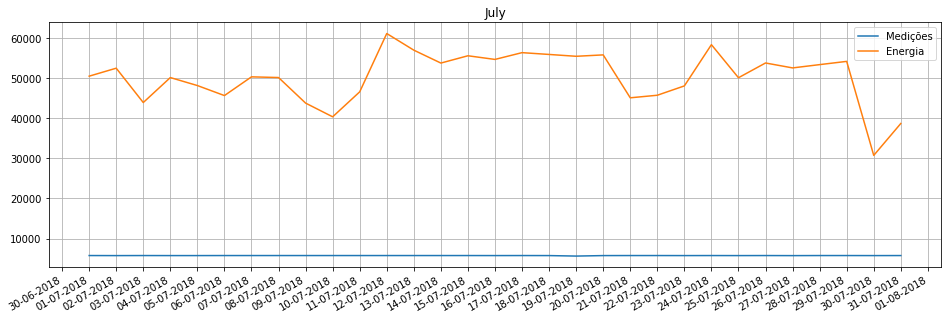

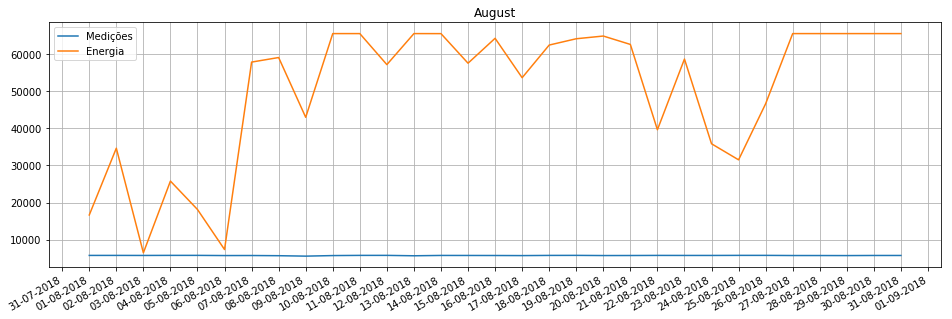

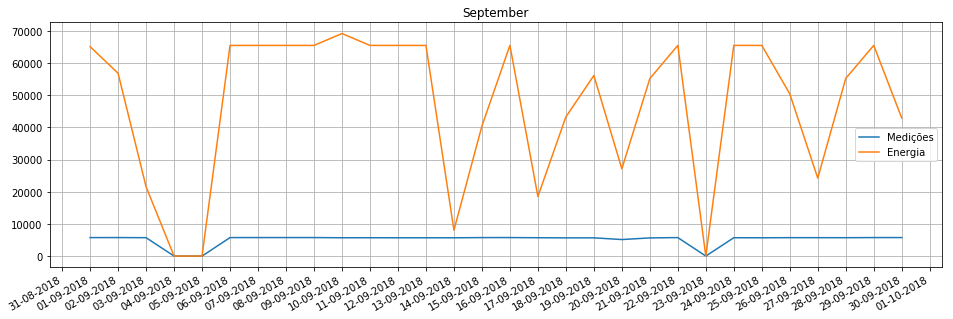

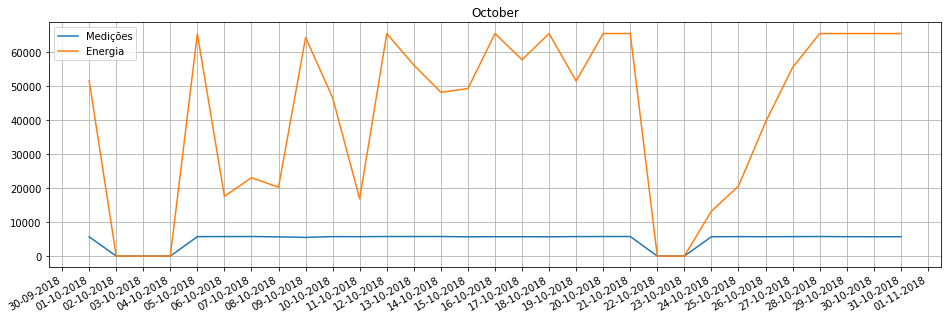

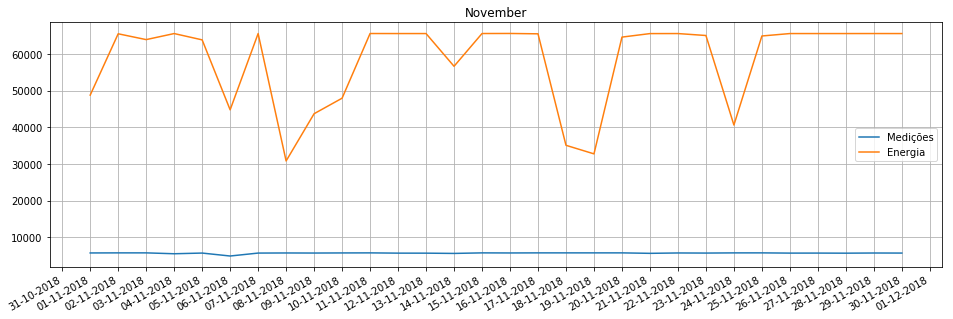

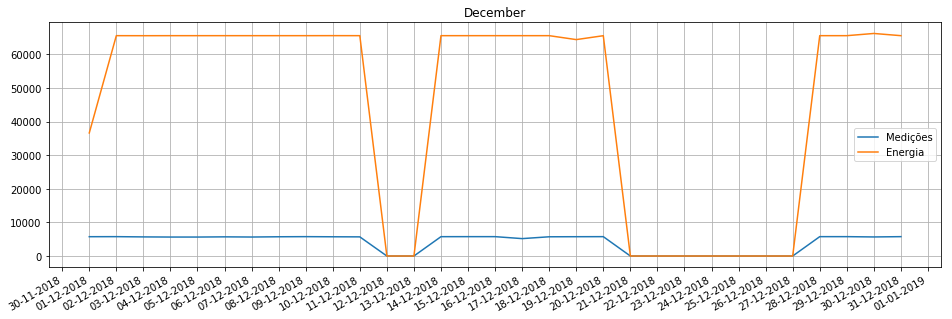

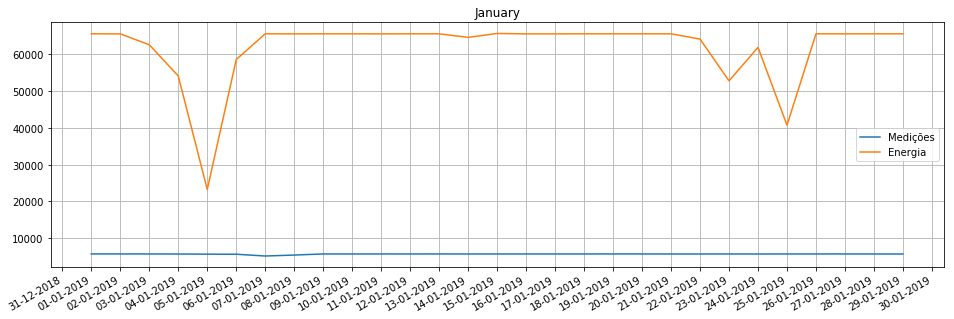

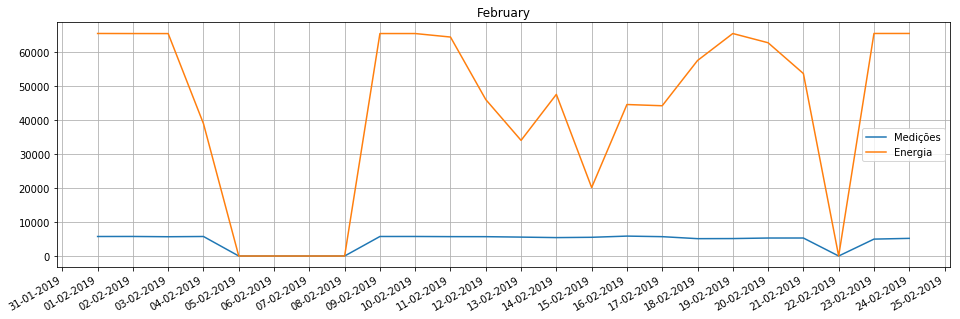

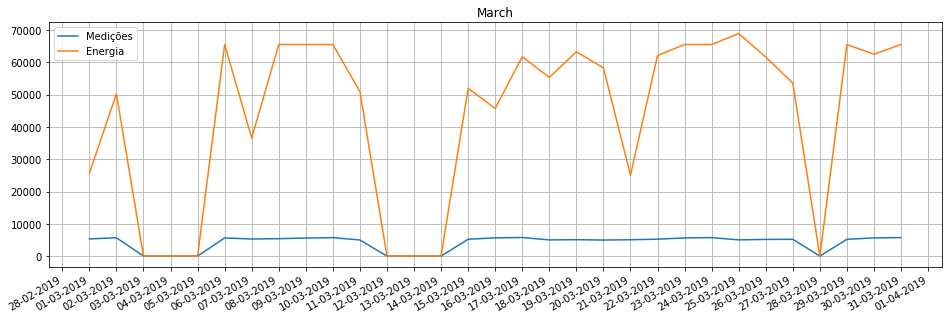

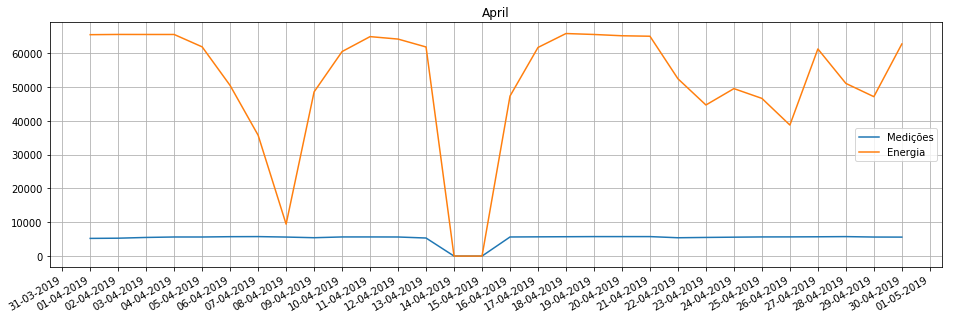

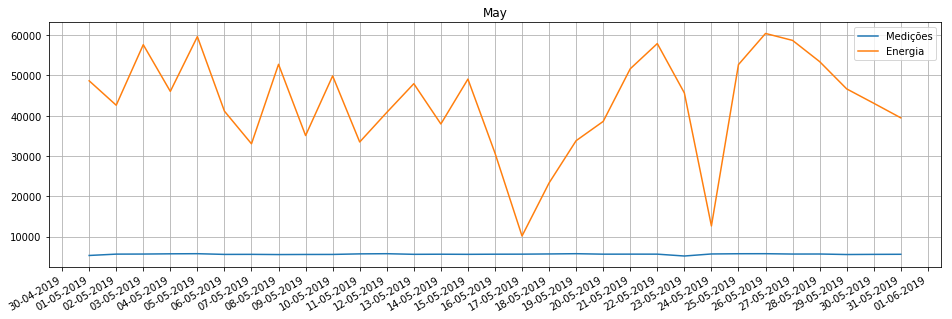

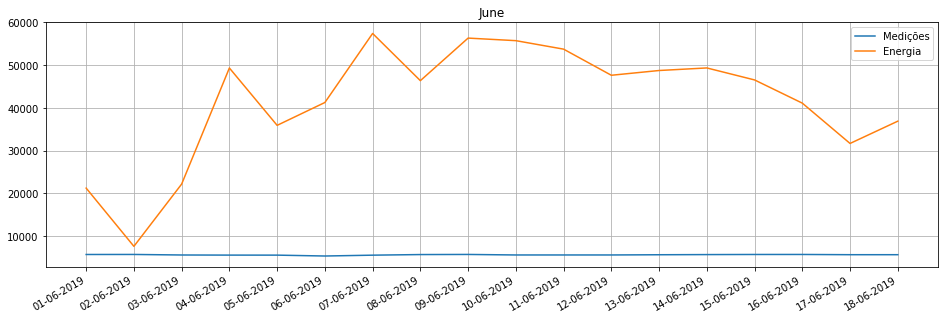

In [20]:
#CÉLULA TCC-20
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month], sort=False):
    plt.figure(figsize=(16,5))
    plt.grid()
    #plt.plot(m[1].groupby(by=[m[1].index.date]).agg({"painel":'size',"energia":'sum'}))
    plt.plot(m[1].resample('D').agg({"painel":'size',"energia":'sum'}))#exibi datas excluidas
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(["Medições","Energia"])
    plt.gca().xaxis.set_major_locator(DayLocator())
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

In [21]:
#CÉLULA TCC-21
#Realizando uma análise da energia acumulada em um dia
period = dfRawFoto1['2019-06-09':'2019-06-09']
print("Total de energia acumulada {:.0f} Wh".format(period.energia.sum()))

trace1 = period.groupby(by=[period.index.hour]).energia.sum().reset_index()
trace = go.Bar(x=trace1['data'],y=trace1['energia'])
data = [trace]
layout = go.Layout(
    title='Energia acumulada por hora',titlefont=dict(size=25),
    xaxis=dict(title='Hora',
                titlefont=dict(size=20),
                ticks='outside',
                tick0=0,
                dtick=1,
                ticklen=5,
                tickwidth=1,
              ),
    yaxis=dict(title='Energia (Wh)',titlefont=dict(size=20)))
iplot(go.Figure(data = [trace], layout=layout))

Total de energia acumulada 56280 Wh


## 1.2 - Análise do dataset meteorológico

In [22]:
#CÉLULA TCC-22
#Identificando todos os datasets referente ao período de quase 1 ano de dados meteorológicos
dataSetMeteorologico = ['Meteorologico_Abr_2019.csv',
'Meteorologico_Ago_2018.csv',
'Meteorologico_Dez_2018.csv',
'Meteorologico_Fev_2019.csv',
'Meteorologico_Jan_2019.csv',
'Meteorologico_Jul_2018.csv',
'Meteorologico_Jun_2019.csv',
'Meteorologico_Mai_2019.csv',
'Meteorologico_Mar_2019.csv',
'Meteorologico_Nov_2018.csv',
'Meteorologico_Out_2018.csv',
'Meteorologico_Sep_2018.csv']

In [23]:
#CÉLULA TCC-23
#Realizando o carregamento dos dados meteorológicos
for idx, data in  enumerate(dataSetMeteorologico):
    path = 'F:\Documentos\Data_Science\TCC\Projeto_final\{}'.format(data)
    if idx == 0:
        dfRawMete = loadDataFile(path, True)
    else:
        dfRawMete = pd.concat([dfRawMete, loadDataFile(path, True)])
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50502 entries, 2019-04-01 00:00:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         50502 non-null float64
deficit_vapor_vmedio       50502 non-null float64
ponto_orvalho_vmin         50502 non-null float64
ponto_orvalho_vmedio       50502 non-null float64
precipitacao_valor         50502 non-null float64
radiacao_solar_valor       50497 non-null float64
temperatura_ar_vmin        50502 non-null float64
temperatura_ar_vmedio      50502 non-null float64
temperatura_ar_vmax        50502 non-null float64
umidade_ar_vmin            50502 non-null float64
umidade_ar_vmedio          50502 non-null float64
umidade_ar_vmax            50502 non-null float64
velocidade_vento_vmedio    50502 non-null float64
velocidade_vento_vmax      50502 non-null float64
dtypes: float64(14)
memory usage: 5.8 MB


In [24]:
#CÉLULA TCC-24
#Selecionando campos
dfRawMete.drop({
    'deficit_vapor_vmin',     #Campo representando a capacidade de absorção de água do ar (valor mínimo);
    #'deficit_vapor_vmedio',  #Campo representando a capacidade de absorção de água do ar (valor médio - °C);
    'ponto_orvalho_vmin',     #Campo representando a temperatura em que fica saturado (valor mínimo - °C);
    #'ponto_orvalho_vmedio',  #Campo representando a temperatura em que fica saturado (valor médio - °C);
    #'precipitacao_valor',    #Campo representando a deposição de água para a superfície da Terra (mm);
    'radiacao_solar_valor',  #Campo representando a energia radiante emitida pelo sol;
    'temperatura_ar_vmin',    #Campo representando a temperatura (valor mínimo - °C);
    #'temperatura_ar_vmedio', #Campo representando a temperatura (valor médio - °C);
    'temperatura_ar_vmax',    #Campo representando a temperatura (valor máximo - °C);
    'umidade_ar_vmin',        #Campo representando a umidade do ar (valor mínimo - %);
    #'umidade_ar_vmedio',     #Campo representando a umidade do ar (valor médio - %);
    'umidade_ar_vmax',        #Campo representando a umidade do ar (valor máximo - %);
    #'velocidade_vento_vmedio',#Campo representando a velocidade do vento (valor médio);
    'velocidade_vento_vmax'   #Campo representando a velocidade do vento (valor máximo);
    },axis=1, inplace=True)

In [25]:
#CÉLULA TCC-25
dfRawMete.isna().sum()

deficit_vapor_vmedio       0
ponto_orvalho_vmedio       0
precipitacao_valor         0
temperatura_ar_vmedio      0
umidade_ar_vmedio          0
velocidade_vento_vmedio    0
dtype: int64

In [26]:
#CÉLULA TCC-26
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [27]:
#CÉLULA TCC-27
#Ordenando o data set pelo index, que representa o campo data
dfRawMete = dfRawMete.sort_index()
dfRawMete.head()

,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
data,,,,,,
2018-07-01 00:00:07,0.33,11.7,0.0,15.18,80.27,0.0
2018-07-01 00:10:07,0.31,12.0,0.0,15.21,81.63,0.0
2018-07-01 00:20:07,0.32,12.0,0.0,15.18,81.43,0.0
2018-07-01 00:30:06,0.31,11.9,0.0,15.05,81.70,0.0
2018-07-01 00:40:07,0.29,11.9,0.0,14.90,82.62,0.0


In [29]:
#CÉLULA TCC-28
#Verificando a quantidade de registros capturados por dia
qtdByDayMete = Counter(dfRawMete.index.date.astype('M8[D]'))
qtdByDayMete

Counter({numpy.datetime64('2018-07-01'): 144,
         numpy.datetime64('2018-07-02'): 144,
         numpy.datetime64('2018-07-03'): 144,
         numpy.datetime64('2018-07-04'): 144,
         numpy.datetime64('2018-07-05'): 144,
         numpy.datetime64('2018-07-06'): 144,
         numpy.datetime64('2018-07-07'): 144,
         numpy.datetime64('2018-07-08'): 144,
         numpy.datetime64('2018-07-09'): 144,
         numpy.datetime64('2018-07-10'): 144,
         numpy.datetime64('2018-07-11'): 144,
         numpy.datetime64('2018-07-12'): 144,
         numpy.datetime64('2018-07-13'): 144,
         numpy.datetime64('2018-07-14'): 144,
         numpy.datetime64('2018-07-15'): 143,
         numpy.datetime64('2018-07-16'): 144,
         numpy.datetime64('2018-07-17'): 144,
         numpy.datetime64('2018-07-18'): 144,
         numpy.datetime64('2018-07-19'): 144,
         numpy.datetime64('2018-07-20'): 143,
         numpy.datetime64('2018-07-21'): 144,
         numpy.datetime64('2018-07

In [30]:
#CÉLULA TCC-29
#Aplicando um teto para descarte de dias com falhas em medições
lstDaysOutMete = []
for i in list(dict.fromkeys(qtdByDayMete.elements())): 
    if qtdByDayMete[i] < 144 * court : # 144 - 10 em 10 minutos, todal de 144 medições por dia
        lstDaysOutMete.append(i.astype(datetime))
lstDaysOutMete

[datetime.date(2018, 8, 19),
 datetime.date(2018, 10, 22),
 datetime.date(2018, 10, 23),
 datetime.date(2018, 12, 1),
 datetime.date(2018, 12, 2),
 datetime.date(2018, 12, 3),
 datetime.date(2018, 12, 4),
 datetime.date(2018, 12, 5),
 datetime.date(2018, 12, 6),
 datetime.date(2018, 12, 7),
 datetime.date(2018, 12, 8),
 datetime.date(2018, 12, 10),
 datetime.date(2018, 12, 11),
 datetime.date(2018, 12, 13),
 datetime.date(2018, 12, 14),
 datetime.date(2018, 12, 15),
 datetime.date(2018, 12, 16),
 datetime.date(2018, 12, 17),
 datetime.date(2019, 2, 11),
 datetime.date(2019, 6, 25)]

In [31]:
#CÉLULA TCC-30
#Removendo dias com medições abaixo do teto
dfRawMete['date'] = dfRawMete.index.date # coluna auxiliar
for i in lstDaysOutMete:# correndo todos os dias com falhas nas medições
    idx = dfRawMete[dfRawMete.date == i].index # obtendo o index
    dfRawMete.drop(idx, inplace=True) # removendo do dataset
dfRawMete.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [32]:
#CÉLULA TCC-31
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48510 entries, 2018-07-01 00:00:07 to 2019-06-24 23:50:06
Data columns (total 6 columns):
deficit_vapor_vmedio       48510 non-null float64
ponto_orvalho_vmedio       48510 non-null float64
precipitacao_valor         48510 non-null float64
temperatura_ar_vmedio      48510 non-null float64
umidade_ar_vmedio          48510 non-null float64
velocidade_vento_vmedio    48510 non-null float64
dtypes: float64(6)
memory usage: 2.6 MB


In [33]:
#CÉLULA TCC-32
#Método responsável por plotar gráficos distintos por colunas
def showDataPlotGroup(dataFrame):
    values = dataFrame.values
    i = 1
    plt.figure(figsize=(15,7))
    plt.title("teste")
    for column in dataFrame.columns:
        plt.subplot(len(dataFrame.columns), 1, i)
        if i == 1:
            plt.title(dataFrame.index.month_name()[0])
        plt.plot(dataFrame[column])
        plt.legend((column,), loc='lower right', bbox_to_anchor=(1.1, -0.1), prop={'size': 11})
        plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
        plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
        plt.gcf().autofmt_xdate()
        plt.yticks(np.arange(0, dataFrame[column].max()+2, step=(dataFrame[column].max()+1)/2))
        i += 1
        plt.grid()

    plt.show()

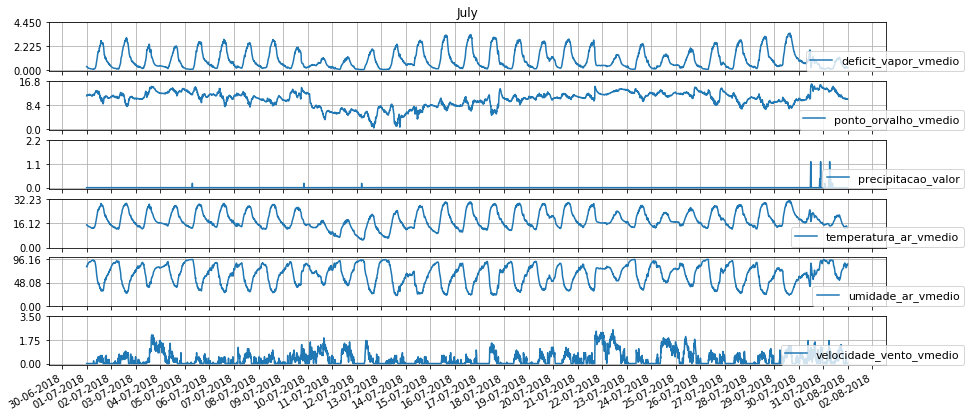

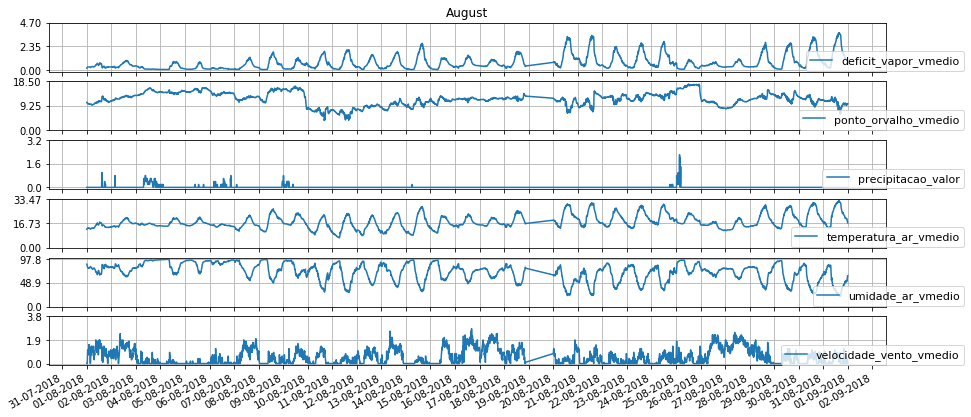

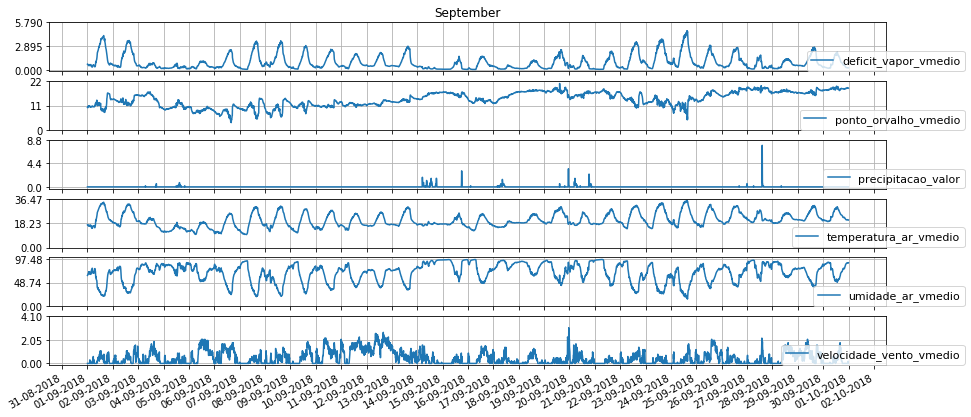

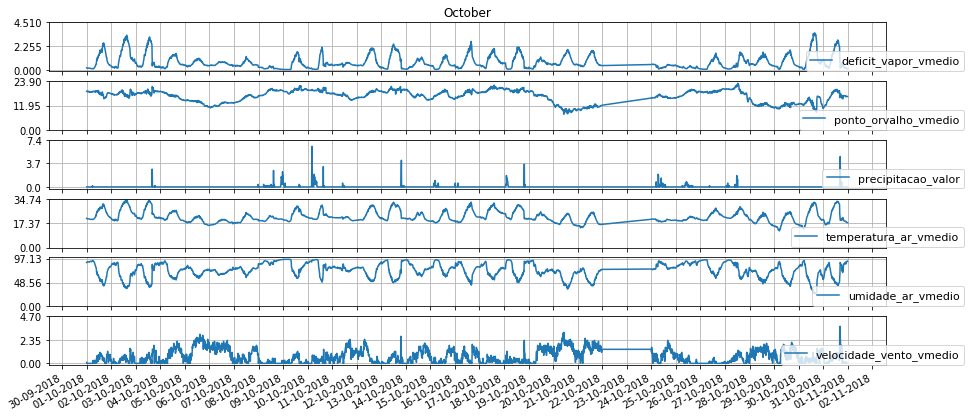

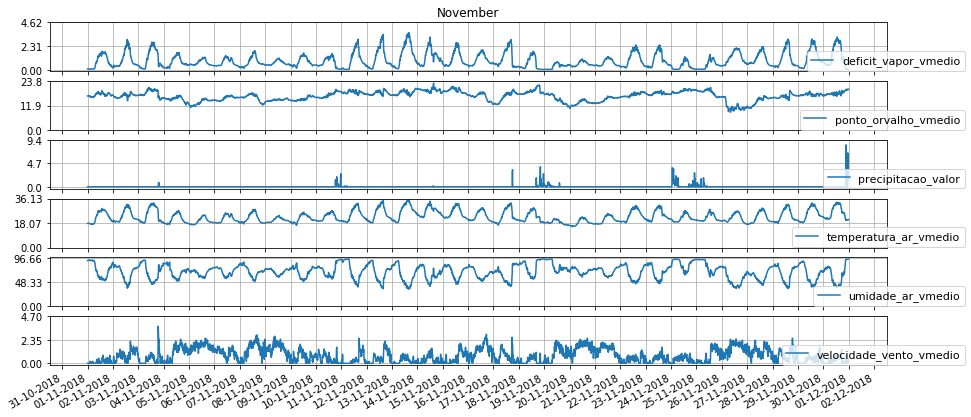

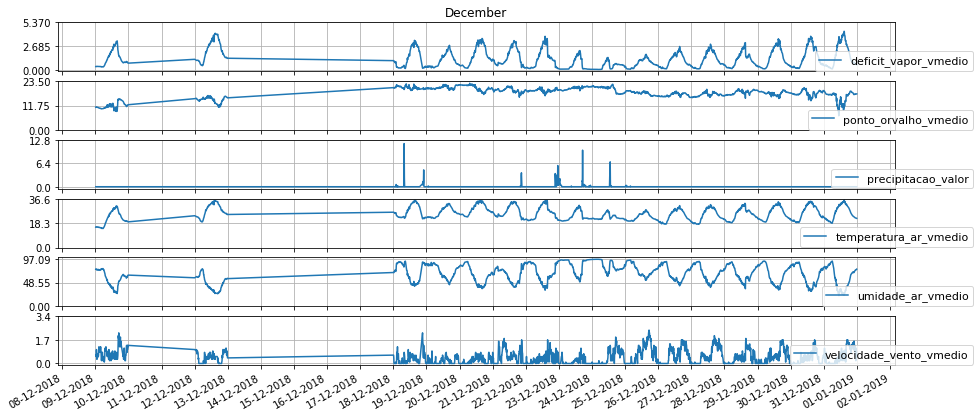

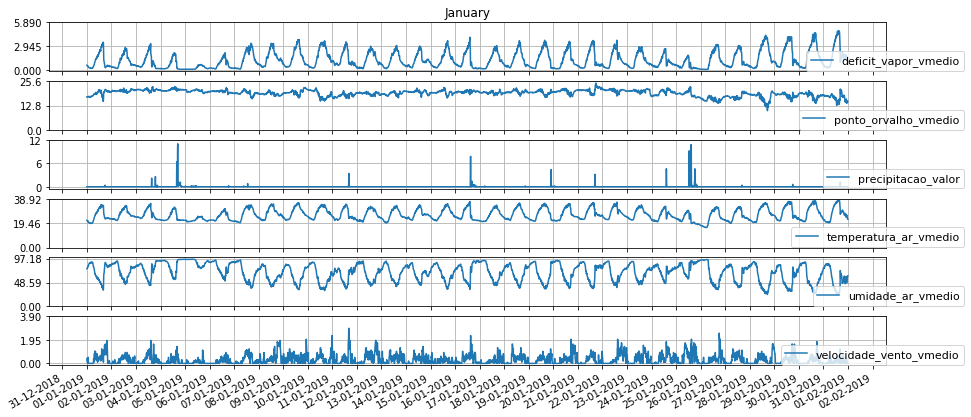

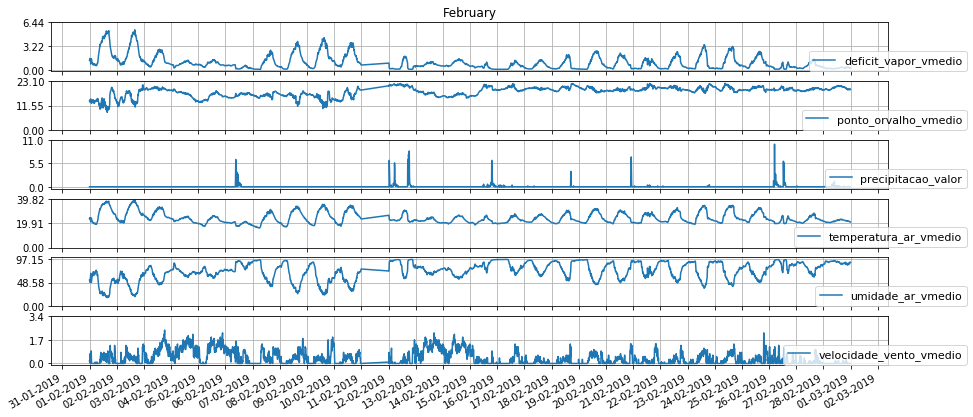

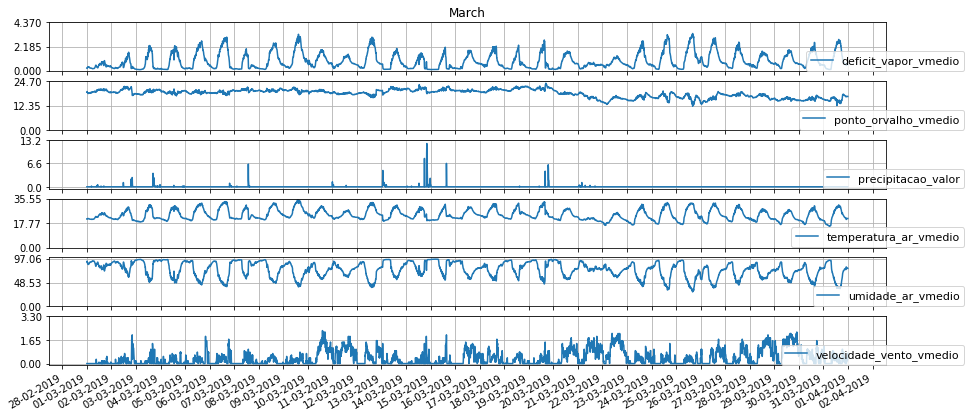

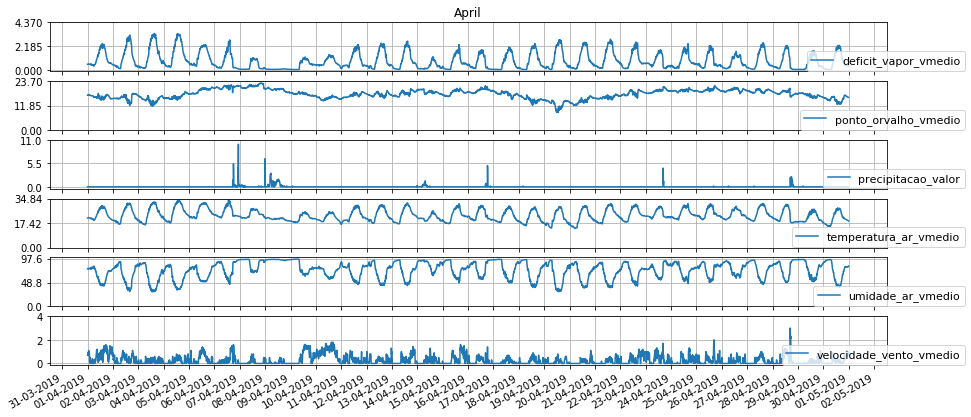

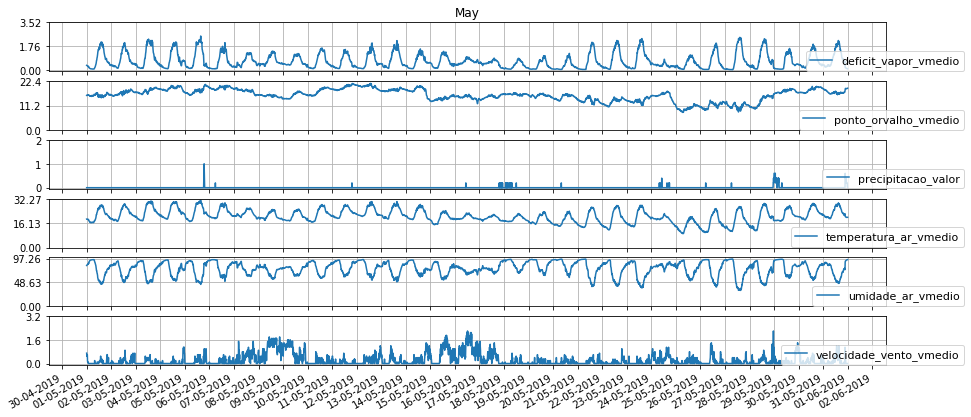

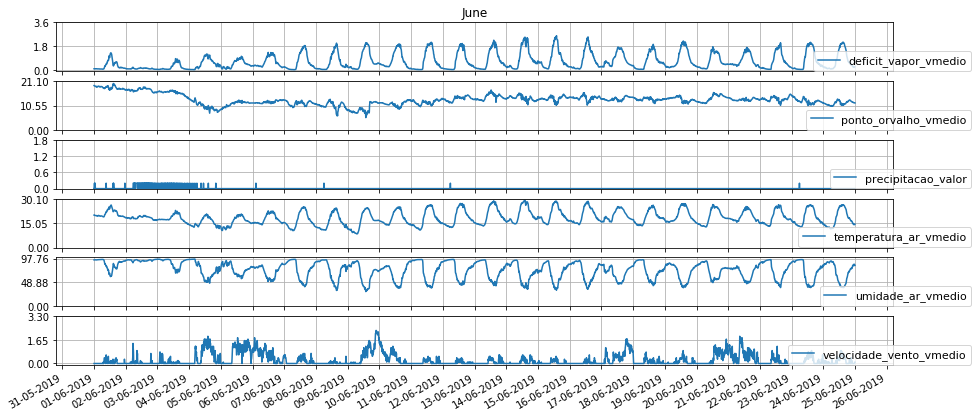

In [35]:
#CÉLULA TCC-33
for m in dfRawMete.groupby(by=[dfRawMete.index.month], sort=False):
    showDataPlotGroup(m[1])
    '''plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    #plt.plot(m[1].groupby(by=[m[1].index.date]).agg({"painel":'size',"energia":'sum'}))
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()'''

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando em média 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando em média 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

## 1.3.1 - DownSample

In [36]:
#CÉLULA TCC-34
dfRawFoto1.head()

,painel,energia
data,,
2018-07-01 00:00:06.897,1.0,0.0
2018-07-01 00:00:10.697,1.0,0.0
2018-07-01 00:00:28.477,1.0,0.0
2018-07-01 00:00:48.993,1.0,0.0
2018-07-01 00:01:07.387,1.0,0.0


In [37]:
#CÉLULA TCC-35
#Realizando ajuste das medicções para uma frequencia padrão de 10 min
freq = '10T' #1D - 1 dia,  10T - 10 min , 60T - 1 h   ou ('60min', on='TIME')

downFoto = dfRawFoto1.resample(freq) #de 10 em 10 minutos cravados
newDownFoto = downFoto.agg({
    "painel":'max',
    "energia":'sum' # realizando a somatória dos valores medidos, para se obter o valor gerado em 10 min
})
interDownFoto = newDownFoto.interpolate(method='linear')
interDownFoto.head()

,painel,energia
data,,
2018-07-01 00:00:00,1.0,0.0
2018-07-01 00:10:00,1.0,0.0
2018-07-01 00:20:00,1.0,0.0
2018-07-01 00:30:00,1.0,0.0
2018-07-01 00:40:00,1.0,0.0


In [38]:
#CÉLULA TCC-36
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50832 entries, 2018-07-01 00:00:00 to 2019-06-18 23:50:00
Freq: 10T
Data columns (total 2 columns):
painel     50832 non-null float64
energia    50832 non-null float64
dtypes: float64(2)
memory usage: 3.7 MB


In [39]:
#CÉLULA TCC-37
#Removendo novamente, pois o resample gera novamente os dias, dias com medições abaixo do teto
interDownFoto['date'] = interDownFoto.index.date # coluna auxiliar
for i in lstDaysOut:# correndo todos os dias com falhas nas medições
    idx = interDownFoto[interDownFoto.date == i].index # obtendo o index
    interDownFoto.drop(idx, inplace=True) # removendo do dataset
interDownFoto.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [40]:
#CÉLULA TCC-38
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 46656 entries, 2018-07-01 00:00:00 to 2019-06-18 23:50:00
Data columns (total 2 columns):
painel     46656 non-null float64
energia    46656 non-null float64
dtypes: float64(2)
memory usage: 1.1 MB


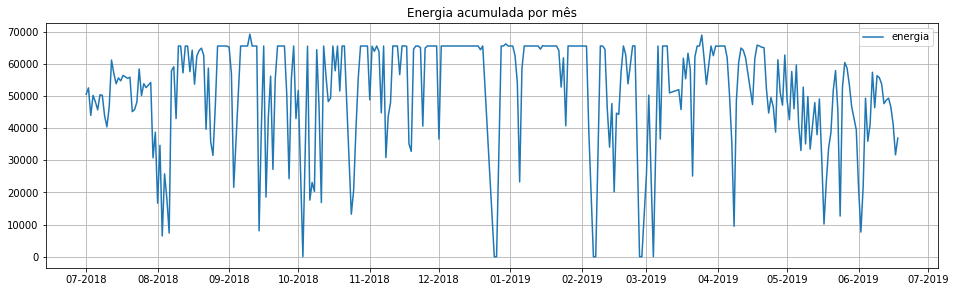

In [41]:
#CÉLULA TCC-39
plt.figure(figsize=(16,5))
plt.title("Energia acumulada por mês")
showDat = interDownFoto.groupby(by=interDownFoto.index.date).agg({"energia":'sum'})
plt.gca().xaxis.set_major_locator(MonthLocator())
plt.gca().xaxis.set_major_formatter(DateFormatter('%m-%Y'))
plt.gcf().autofmt_xdate()
showDataPlot(showDat)

## 1.3.2 - UpSample

In [42]:
#CÉLULA TCC-40
downMete = dfRawMete.resample(freq) #de 10 em 10 minutos cravados
newDownMete = downMete.agg({
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'velocidade_vento_vmedio':'mean',
    'temperatura_ar_vmedio':'mean',
    'umidade_ar_vmedio':'mean',
})
interDownMete = newDownMete.interpolate(method='linear')
interDownMete.head()

,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,velocidade_vento_vmedio,temperatura_ar_vmedio,umidade_ar_vmedio
data,,,,,,
2018-07-01 00:00:00,0.33,11.7,0.0,0.0,15.18,80.27
2018-07-01 00:10:00,0.31,12.0,0.0,0.0,15.21,81.63
2018-07-01 00:20:00,0.32,12.0,0.0,0.0,15.18,81.43
2018-07-01 00:30:00,0.31,11.9,0.0,0.0,15.05,81.70
2018-07-01 00:40:00,0.29,11.9,0.0,0.0,14.90,82.62


In [43]:
#CÉLULA TCC-41
interDownMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 51696 entries, 2018-07-01 00:00:00 to 2019-06-24 23:50:00
Freq: 10T
Data columns (total 6 columns):
deficit_vapor_vmedio       51696 non-null float64
ponto_orvalho_vmedio       51696 non-null float64
precipitacao_valor         51696 non-null float64
velocidade_vento_vmedio    51696 non-null float64
temperatura_ar_vmedio      51696 non-null float64
umidade_ar_vmedio          51696 non-null float64
dtypes: float64(6)
memory usage: 5.3 MB


In [44]:
#CÉLULA TCC-42
#Removendo novamente, pois o resample gera novamente os dias, dias com medições abaixo do teto
interDownMete['date'] = interDownMete.index.date # coluna auxiliar
for i in lstDaysOutMete:# correndo todos os dias com falhas nas medições
    idx = interDownMete[interDownMete.date == i].index # obtendo o index
    interDownMete.drop(idx, inplace=True) # removendo do dataset
interDownMete.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [45]:
#CÉLULA TCC-43
interDownMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48960 entries, 2018-07-01 00:00:00 to 2019-06-24 23:50:00
Data columns (total 6 columns):
deficit_vapor_vmedio       48960 non-null float64
ponto_orvalho_vmedio       48960 non-null float64
precipitacao_valor         48960 non-null float64
velocidade_vento_vmedio    48960 non-null float64
temperatura_ar_vmedio      48960 non-null float64
umidade_ar_vmedio          48960 non-null float64
dtypes: float64(6)
memory usage: 2.6 MB


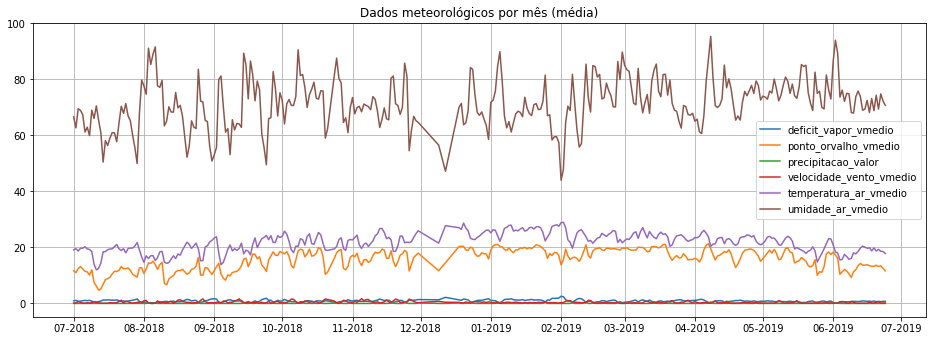

In [47]:
#CÉLULA TCC-44
plt.figure(figsize=(16,6))
plt.title("Dados meteorológicos por mês (média)")
showDat = interDownMete.groupby(by=interDownMete.index.date).agg({
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'velocidade_vento_vmedio':'mean',
    'temperatura_ar_vmedio':'mean',
    'umidade_ar_vmedio':'mean'
})
plt.gca().xaxis.set_major_locator(MonthLocator())
plt.gca().xaxis.set_major_formatter(DateFormatter('%m-%Y'))
plt.gcf().autofmt_xdate()
showDataPlot(showDat)

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível agrupar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [48]:
#CÉLULA TCC-45
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
dfSet1.reset_index(inplace=True)

In [49]:
#CÉLULA TCC-46
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44352 entries, 0 to 44351
Data columns (total 9 columns):
data                       44352 non-null datetime64[ns]
painel                     44352 non-null float64
energia                    44352 non-null float64
deficit_vapor_vmedio       44352 non-null float64
ponto_orvalho_vmedio       44352 non-null float64
precipitacao_valor         44352 non-null float64
velocidade_vento_vmedio    44352 non-null float64
temperatura_ar_vmedio      44352 non-null float64
umidade_ar_vmedio          44352 non-null float64
dtypes: datetime64[ns](1), float64(8)
memory usage: 3.0 MB


In [50]:
#CÉLULA TCC-47
#Salvando o dataset
saveDataFile(dfSet1,'input/FotoMet_P1_DataSets_10T.csv')

Com os dados preparados, é possível dar continuidade no trabalho para inicio da geração dos modelos

In [51]:
#CÉLULA TCC-48
#Estrutura respnsável por carregar um dataset no formato csv
#FotoMet_P1_DataSets_10T.csv - 44352 registros - 308 dias
#FotoMet_P2_DataSets_10T.csv - 43920 registros - 305 dias
#FotoMet_P3_DataSets_10T.csv - 43920 registros - 305 dias
#FotoMet_P4_DataSets_10T.csv - 44352 registros - 308 dias
dfSet1 = loadDataFile('input/FotoMet_P1_DataSets_10T.csv', True)

In [52]:
#CÉLULA TCC-49
allData = dfSet1
allData = allData.groupby(by=allData.index.date).agg({
    'energia':'sum',
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'velocidade_vento_vmedio':'mean',
    'temperatura_ar_vmedio':'mean',
    'umidade_ar_vmedio':'mean'
})

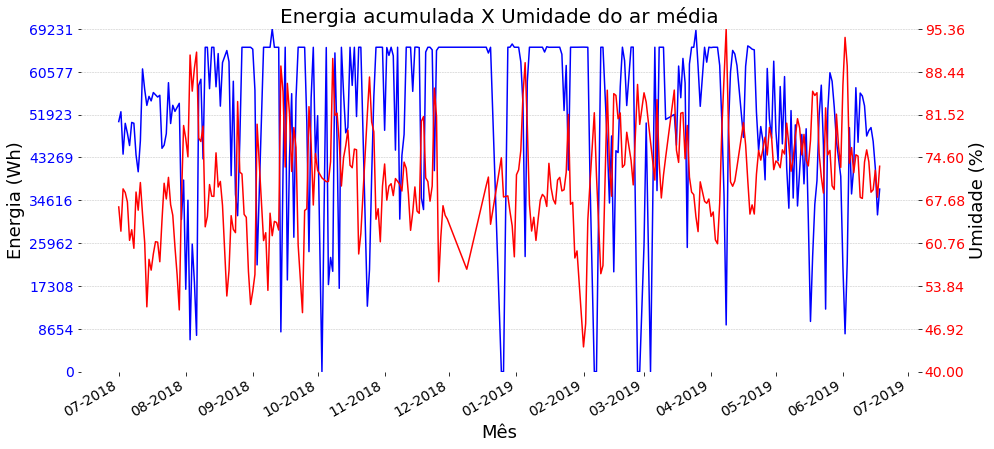

In [53]:
#CÉLULA TCC-50
#Exibição de dados da nova tabela
x_values = allData.index
y_values_1 = allData.energia

fig, ax1 = plt.subplots(figsize=(15,7))  
title = ('Energia acumulada X Umidade do ar média')

plt.title(title, fontsize=20)
plt.grid(axis='y',color='grey', linestyle='--', lw=0.5, alpha=0.5)
plt.tick_params(axis='both', labelsize=14)

plot1 = ax1.plot(x_values, y_values_1, 'b', label='Energia')
ax1.set_ylabel('Energia (Wh)', fontsize=18)
ax1.set_xlabel('Mês', fontsize=18)
ax1.set_ylim(0,y_values_1.max()+1)
for tl in ax1.get_yticklabels():
    tl.set_color('b')

ax2 = ax1.twinx()
y_values_2 = allData['umidade_ar_vmedio']
plot2 = ax2.plot(x_values, y_values_2, 'r', label='Umidade')

ax2.set_ylabel('Umidade (%)', fontsize=18)
ax2.set_ylim(40, y_values_2.max().max())
ax2.tick_params(axis='y', labelsize=14)
for tl in ax2.get_yticklabels():
    tl.set_color('r')

lines = plot1 + plot2

ax1.set_yticks(np.linspace(ax1.get_ybound()[0], ax1.get_ybound()[1], 9))
ax2.set_yticks(np.linspace(ax2.get_ybound()[0], ax2.get_ybound()[1], 9))

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)  
    ax.spines["bottom"].set_visible(False)  
    ax.spines["right"].set_visible(False)  
    ax.spines["left"].set_visible(False) 
    
plt.gca().xaxis.set_major_locator(MonthLocator())
plt.gca().xaxis.set_major_formatter(DateFormatter('%m-%Y'))
plt.gcf().autofmt_xdate()

plt.show()

In [54]:
#CÉLULA TCC-51
dfSet1.describe()
#dfSet1['energia'].sum()
#1- 15789723.0
#2- 11704131.0
#3- 14946955.0
#4- 12525875.0

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,velocidade_vento_vmedio,temperatura_ar_vmedio,umidade_ar_vmedio
count,44352.0,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000
mean,1.0,356.009673,0.884598,15.656119,0.027618,0.426033,21.759375,71.353038
std,0.0,604.254185,0.798892,3.733721,0.284130,0.540729,5.180695,17.506452
min,1.0,0.000000,0.040000,0.500000,0.000000,0.000000,5.140000,15.560000
25%,1.0,0.000000,0.300000,12.800000,0.000000,0.000000,18.350000,59.540000
50%,1.0,0.000000,0.590000,16.300000,0.000000,0.200000,21.310000,74.650000
75%,1.0,576.000000,1.250000,18.700000,0.000000,0.700000,25.140000,85.380000
max,1.0,9297.000000,5.440000,24.600000,11.800000,3.700000,38.820000,96.800000


In [55]:
#CÉLULA TCC-52
dfSet1.head()

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,velocidade_vento_vmedio,temperatura_ar_vmedio,umidade_ar_vmedio
data,,,,,,,,
2018-07-01 00:00:00,1.0,0.0,0.33,11.7,0.0,0.0,15.18,80.27
2018-07-01 00:10:00,1.0,0.0,0.31,12.0,0.0,0.0,15.21,81.63
2018-07-01 00:20:00,1.0,0.0,0.32,12.0,0.0,0.0,15.18,81.43
2018-07-01 00:30:00,1.0,0.0,0.31,11.9,0.0,0.0,15.05,81.70
2018-07-01 00:40:00,1.0,0.0,0.29,11.9,0.0,0.0,14.90,82.62


## 2 - Normalização

Necessário normalizar os dados, pois estão dernormalizados

In [56]:
#CÉLULA TCC-53
dfSet1 = dfSet1.reset_index()
df = dfSet1.drop(['data'],axis=1)

In [57]:
#CÉLULA TCC-54
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,energia,deficit_vapor_vmedio,ponto_orvalho_vmedio,precipitacao_valor,velocidade_vento_vmedio,temperatura_ar_vmedio,umidade_ar_vmedio
count,44352.0,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000
mean,0.0,0.038293,0.156407,0.628885,0.002340,0.115144,0.493449,0.686768
std,0.0,0.064995,0.147943,0.154926,0.024079,0.146143,0.153821,0.215491
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.048148,0.510373,0.000000,0.000000,0.392221,0.541359
50%,0.0,0.000000,0.101852,0.655602,0.000000,0.054054,0.480107,0.727351
75%,0.0,0.061955,0.224074,0.755187,0.000000,0.189189,0.593824,0.859429
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 3 - Definição do modelo

Nessa etapa, serão utilizado alguns modelos, realizado assim os treinamentos e análisando os resultados obtidos perantes aos dados.
Primeiramente, será abordado modelos lineares.
As métricas utilizadas a fim da verificação e comparação dos modelos são:
- MSE - Representa o erro médio quadrático, uma métrica de risco correspondente ao valor esperado do erro ou perda quadrática (quadrática).
- RMSE - Representa o desvio padrão da amostra das diferenças entre os valores previstos e os valores observados (chamados resíduos).
- r² - Coeficiente de Determinação, diz o quanto meu modelo está prevendo corretamente.
- MAE - Representa a média da diferença absoluta entre os valores previstos e o valor observado

In [58]:
#CÉLULA TCC-55
#Imports necessários para análise dos modelos
import seaborn as sns
from math import sqrt

from sklearn import model_selection, linear_model
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from keras.models import Sequential

from sklearn import metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.preprocessing import MinMaxScaler
from keras.layers import Dense, LSTM, Dropout

import keras as K
import tensorflow as tf

G:\Programas\Anaconda\lib\site-packages\h5py\__init__.py:36: FutureWarning:

Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.

Using TensorFlow backend.


In [59]:
#CÉLULA TCC-56
#Método responsável por plotar o pair plot
def showPairPlot(dataFrame):

    pairPlot = sns.pairplot(
        dataFrame,
        size=2.0,
        aspect=1.4,
        plot_kws=dict(edgecolor="k", linewidth=0.2),
        diag_kws=dict(shade=True),        
        diag_kind="kde",
    )               
                 
    fig = pairPlot.fig
    fig.subplots_adjust(top=0.95)
    fig.suptitle(
        'Análise de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [60]:
#CÉLULA TCC-57
#Método responsável por plotar o heatmap
def showHeatMap(dataFrame):
    
    fig, (ax) = plt.subplots(1, 1, figsize=(11,7))
    heatMap = sns.heatmap(
        dataFrame.corr(), 
        ax=ax,           
        cmap="coolwarm",
        annot=True, 
        fmt='.2f',
        linewidths=.07
    )

    fig.suptitle(
        'Correlação de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [61]:
#CÉLULA TCC-58
#Método responsável por plotar os resultados de testes
def showResultPlot(y_pred,y_test):   
    dfteste = pd.DataFrame({'Atual': y_test, 'Previsto': y_pred})
    dfTesteShow = dfteste.head(30)
    dfTesteShow.plot(kind='bar', figsize=(15,7), title='Exibição dos 30 primeiros dados de testes previstos')
    plt.grid()
    plt.show()
    '''y_pred = y_pred.T
    
    plt.plot(range(len(y_test)), y_test, 'b+-')
    plt.plot(range(len(y_pred)), y_pred, 'ro-')
    plt.gca().legend(('Real','Previsão'))

    plt.grid()
    plt.show()'''

In [62]:
#CÉLULA TCC-59
#Método responsável por treinar os modelos e exibir as métricas utilizadas para comparação dos mesmos
def showResult(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)
    y_pred_Train = model.predict(X_train)
    y_pred_Test = model.predict(X_test)

    #print(model)# exibição dos parametros utilizados no modelo
    print('------------------- TREINO -------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_train, y_pred_Train)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_train, y_pred_Train))))
    #print('r²: {:.2f} %'.format(model.score(X_train, y_train) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_train, y_pred_Train) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_train, y_pred_Train)))
    print('------------------- TESTE ---------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_test, y_pred_Test)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred_Test))))
    #print('r²: {:.2f} %'.format(model.score(X_test, y_test) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_test, y_pred_Test) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_test, y_pred_Test)))

    print('----------------------------------------------------')
    showResultPlot(y_pred_Test,y_test)  
    
    return model

In [63]:
#CÉLULA TCC-60
dfParameters = df.drop(['painel'],axis=1)

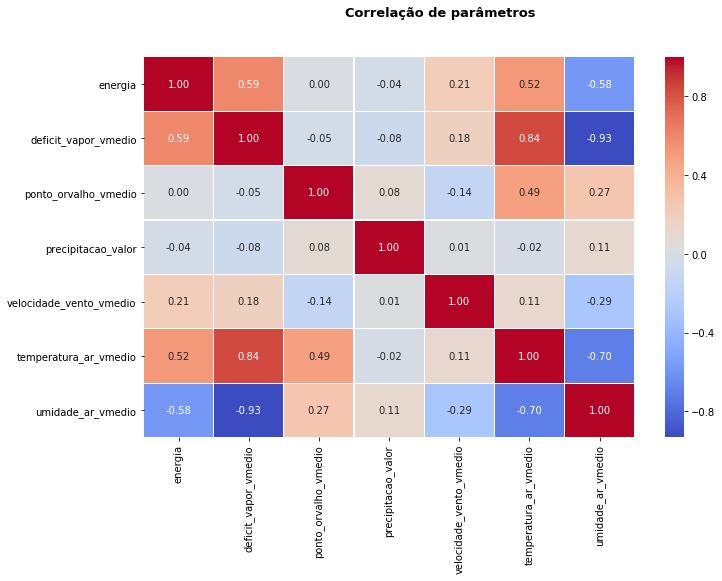

In [64]:
#CÉLULA TCC-61
showHeatMap(dfParameters)

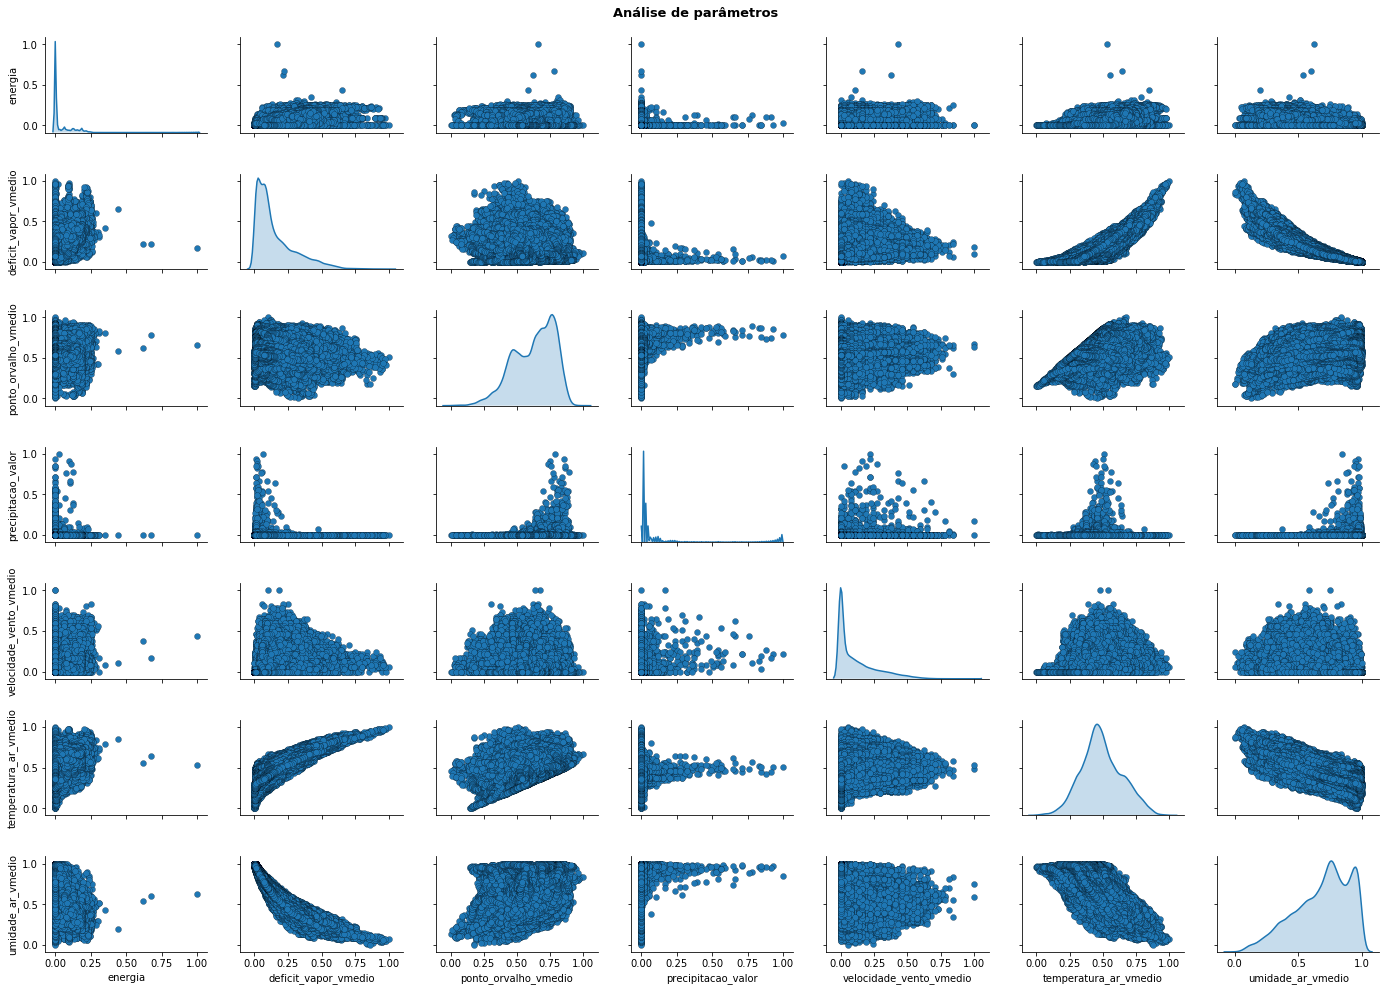

In [65]:
#CÉLULA TCC-62
showPairPlot(dfParameters)

In [66]:
#CÉLULA TCC-63
#Definindo o target como o campo 'energia'
X = dfParameters.drop(['energia'],axis=1)
y = dfParameters.energia

In [67]:
#CÉLULA TCC-64
#Realizando divisão em dados de treino e teste
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.25, random_state=42)

In [68]:
#CÉLULA TCC-65
print('Dados de treino')
print('----------------')
print(X_train.shape)
print(y_train.shape)
print('----------------')
print('Dados de teste')
print('----------------')
print(X_test.shape)
print(y_test.shape)

Dados de treino
----------------
(33264, 6)
(33264,)
----------------
Dados de teste
----------------
(11088, 6)
(11088,)


## Regressão  Linear
Regressão linear usa os pontos de dados para encontrar a melhor linha de ajuste para modelar os dados.

----------------------------------------------------
----------      REGRESSÃO LINEAR       -------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.002629
RMSE: 0.051274
r²: 37.84 %
MAE: 0.037325
------------------- TESTE ---------------------------
MSE: 0.002693
RMSE: 0.051899
r²: 35.99 %
MAE: 0.037775
----------------------------------------------------


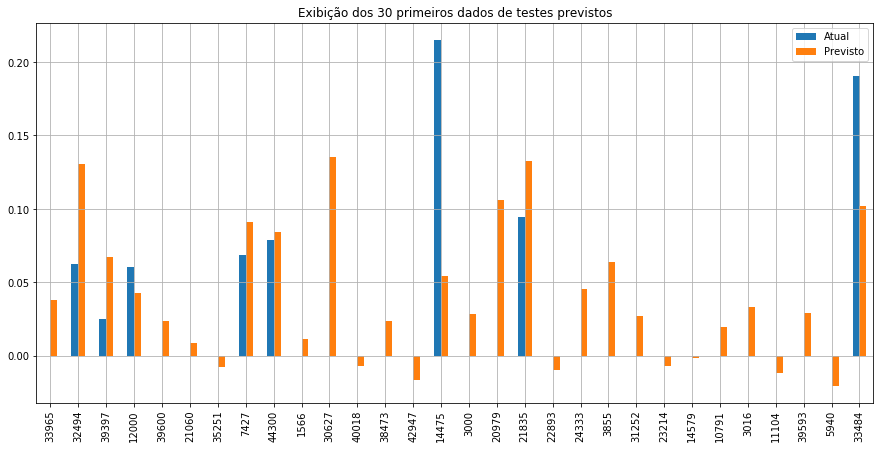

                         0  Coeficiente estimado
0     deficit_vapor_vmedio              0.253467
1     ponto_orvalho_vmedio              0.205780
2       precipitacao_valor              0.035905
3  velocidade_vento_vmedio              0.032645
5        umidade_ar_vmedio             -0.175146
4    temperatura_ar_vmedio             -0.258478


In [69]:
#CÉLULA TCC-66
LinearRegression = linear_model.LinearRegression()

print('----------------------------------------------------')
print('----------      REGRESSÃO LINEAR       -------------')
print('----------------------------------------------------')

modelLinearRegression = showResult(LinearRegression, X_train, y_train, X_test, y_test)

coeff = pd.DataFrame(X_train.columns)
coeff['Coeficiente estimado'] = pd.Series(modelLinearRegression.coef_)
coeff.sort_values(by='Coeficiente estimado', inplace=True, ascending=False)
print(coeff)

## Random Forest Regressor
Este algoritmo de florestas aleatórias, gera várias árvores de decisão e a combinação delas é utilizada para se obter uma maior acurácia e uma maior estabilidade.

Encontrando os melhores parâmetros.

In [70]:
#CÉLULA TCC-67
rfr = RandomForestRegressor()

parameters = {
    'max_depth': [12, 13, 14],#número máximo de levels para cada arvore de decisão
    'max_features': ['sqrt'],
    'min_samples_split': [2,3,4],
    'min_samples_leaf': [5, 7],
    'n_estimators': [175, 200, 225 ,250]#número de árvores da floresta
}

rfr_grid = GridSearchCV(
    rfr,
    parameters,
    cv = 2,
    n_jobs = 5,
    verbose=True
)

rfr_grid.fit(X_train,y_train)

print(rfr_grid.best_score_)
print(rfr_grid.best_params_)

Fitting 2 folds for each of 72 candidates, totalling 144 fits


[Parallel(n_jobs=5)]: Using backend LokyBackend with 5 concurrent workers.
[Parallel(n_jobs=5)]: Done  40 tasks      | elapsed:  1.1min
[Parallel(n_jobs=5)]: Done 144 out of 144 | elapsed:  3.6min finished


0.4936230313820427
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 225}


----------------------------------------------------
------------      RANDOM FOREST     ----------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.001639
RMSE: 0.040486
r²: 61.25 %
MAE: 0.025720
------------------- TESTE ---------------------------
MSE: 0.002132
RMSE: 0.046169
r²: 49.34 %
MAE: 0.029339
----------------------------------------------------


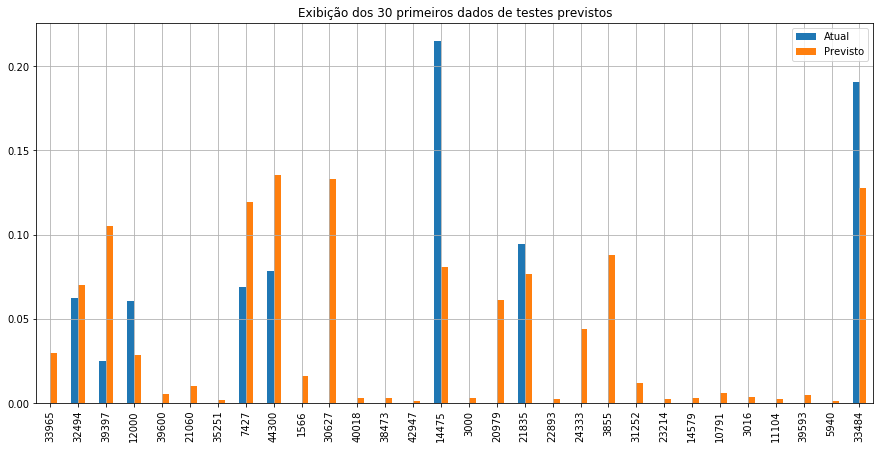

In [71]:
#CÉLULA TCC-68
RandomForest = RandomForestRegressor(
    max_depth = 13,
    max_features = 'sqrt',
    min_samples_split = 3,
    min_samples_leaf = 5,
    n_estimators = 250
)
    
print('----------------------------------------------------')
print('------------      RANDOM FOREST     ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(RandomForest, X_train, y_train, X_test, y_test)

## XGBRegressor
É uma implementação de árvores de decisão aprimoradas por gradiente.

Encontrando os melhores parâmetros.

In [72]:
#CÉLULA TCC-69
xgbReg = xgb.XGBRegressor()

parameters = {
    'nthread':[4],
    'objective':['reg:linear'],
    'learning_rate': [.03],
    'max_depth': [5, 6,8, 10],
    'min_child_weight': [5,6,7],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.7],
    'n_estimators': [225, 250, 275, 300]
}

xgb_grid = GridSearchCV(
    xgbReg,
    parameters,
    cv = 2,
    n_jobs = 5,
    verbose=True
)

xgb_grid.fit(X_train,y_train)

print(xgb_grid.best_score_)
print(xgb_grid.best_params_)

Fitting 2 folds for each of 96 candidates, totalling 192 fits


[Parallel(n_jobs=5)]: Using backend LokyBackend with 5 concurrent workers.
[Parallel(n_jobs=5)]: Done  40 tasks      | elapsed:   58.7s
[Parallel(n_jobs=5)]: Done 192 out of 192 | elapsed:  5.9min finished
G:\Programas\Anaconda\lib\site-packages\xgboost\core.py:587: FutureWarning:

Series.base is deprecated and will be removed in a future version



0.4915217549306414
{'colsample_bytree': 0.7, 'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 225, 'nthread': 4, 'objective': 'reg:linear', 'subsample': 0.8}


----------------------------------------------------
------------           XGB          ----------------
----------------------------------------------------


G:\Programas\Anaconda\lib\site-packages\xgboost\core.py:587: FutureWarning:

Series.base is deprecated and will be removed in a future version



------------------- TREINO -------------------------
MSE: 0.001983
RMSE: 0.044532
r²: 53.11 %
MAE: 0.029092
------------------- TESTE ---------------------------
MSE: 0.002155
RMSE: 0.046425
r²: 48.78 %
MAE: 0.030242
----------------------------------------------------


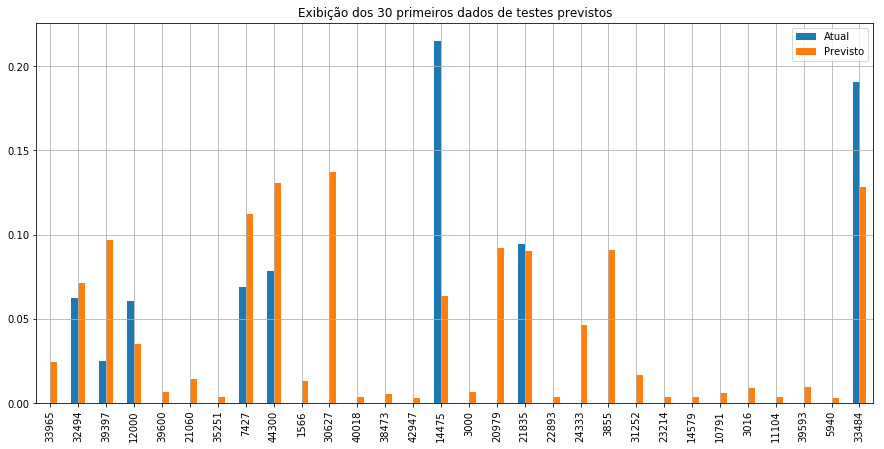

In [73]:
#CÉLULA TCC-70
xgbReg = xgb.XGBRegressor(
    nthread = 4,
    objective = 'reg:linear',
    learning_rate = .03,
    max_depth = 5,
    min_child_weight = 5,
    subsample = 0.8,
    colsample_bytree = 0.7,
    n_estimators = 225
)
    
print('----------------------------------------------------')
print('------------           XGB          ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(xgbReg, X_train, y_train, X_test, y_test)

Uma outra abordagem, realizando o uso de rede neural, considerando os dados como uma série temporal.

## Long Short Term Memory
É uma arquitetura de rede neural recorrente.

In [74]:
#CÉLULA TCC-71
# convertendo series para aprendizado supervisionado
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
    n_vars = 1 if type(data) is list else data.shape[1]
    df = pd.DataFrame(data)
    cols, names = list(), list()
    # input sequence (t-n, ... t-1)
    for i in range(n_in, 0, -1):
        cols.append(df.shift(i))
        names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
    # forecast sequence (t, t+1, ... t+n)
    for i in range(0, n_out):
        cols.append(df.shift(-i))
        if i == 0:
            names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
        else:
            names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
    agg = pd.concat(cols, axis=1)
    agg.columns = names
    if dropnan:
        agg.dropna(inplace=True)
    return agg

In [7]:
#CÉLULA TCC-72
#Carregando novamente o csv
df = loadDataFile('input/FotoMet_P1_DataSets_10T.csv', True)
dataset = dataset[['energia','temperatura_ar_vmedio','umidade_ar_vmedio']]
#df = df[['energia']]

NameError: name 'dataset' is not defined

In [ ]:
#CÉLULA TCC-73
#Normalizando os dados
min_max_scaler = MinMaxScaler(feature_range=(0, 1))
scalerDf = min_max_scaler.fit_transform(df.values.astype('float32'))

In [ ]:
#CÉLULA TCC-74
#Convertendo serie para um modelo supervisionado
newDf = series_to_supervised(scalerDf, 1, 1)
#newDf.drop(newDf.columns[[4,5]], axis=1, inplace=True)
print(newDf.head())

In [78]:
#CÉLULA TCC-75
# Dividindo os dados em treino e teste
values = newDf.values
n_division = int(len(values) * 0.85)
train = values[:n_division, :]
test = values[n_division:, :]

# Realizando split das entradas e saída
X_train, y_train = train[:, :-1], train[:, -1]
X_test, y_test = test[:, :-1], test[:, -1]

# Realizando o reshap da entrada para ser 3D para a LSTM [samples, timesteps, features]
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(37698, 1, 1) (37698,) (6653, 1, 1) (6653,)


In [79]:
#CÉLULA TCC-76
#Definindo a rede

#Limpa o modelo previamente usado
K.backend.clear_session()
tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

model = Sequential()
model.add(LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae', 'mse'])
model.summary()

W0930 18:17:46.415070  9912 deprecation_wrapper.py:119] From C:\Users\Léo\AppData\Roaming\Python\Python36\site-packages\keras\backend\tensorflow_backend.py:95: The name tf.reset_default_graph is deprecated. Please use tf.compat.v1.reset_default_graph instead.

W0930 18:17:46.417068  9912 deprecation_wrapper.py:119] From C:\Users\Léo\AppData\Roaming\Python\Python36\site-packages\keras\backend\tensorflow_backend.py:98: The name tf.placeholder_with_default is deprecated. Please use tf.compat.v1.placeholder_with_default instead.

W0930 18:17:47.229489  9912 deprecation_wrapper.py:119] From C:\Users\Léo\AppData\Roaming\Python\Python36\site-packages\keras\backend\tensorflow_backend.py:102: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.



_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm_1 (LSTM)                (None, 50)                10400     
_________________________________________________________________
dense_1 (Dense)              (None, 1)                 51        
Total params: 10,451
Trainable params: 10,451
Non-trainable params: 0
_________________________________________________________________


In [80]:
#CÉLULA TCC-77
#Treinando a rede
max_epochs = 50
batch_size = 72
print("Iniciando treinamento... ")
h = model.fit(X_train, y_train, epochs=max_epochs, batch_size=batch_size, validation_data=(X_test, y_test), verbose=1, shuffle=False)
print("Treinamento finalizado \n")

Iniciando treinamento... 
Train on 37698 samples, validate on 6653 samples
Epoch 1/50
37698/37698 [==============================] - 5s 127us/step - loss: 0.0012 - mean_absolute_error: 0.0208 - mean_squared_error: 0.0012 - val_loss: 3.1006e-04 - val_mean_absolute_error: 0.0089 - val_mean_squared_error: 3.1006e-04
Epoch 2/50
37698/37698 [==============================] - 1s 40us/step - loss: 5.2141e-04 - mean_absolute_error: 0.0098 - mean_squared_error: 5.2141e-04 - val_loss: 3.0984e-04 - val_mean_absolute_error: 0.0089 - val_mean_squared_error: 3.0984e-04
Epoch 3/50
37698/37698 [==============================] - 2s 50us/step - loss: 5.1907e-04 - mean_absolute_error: 0.0098 - mean_squared_error: 5.1907e-04 - val_loss: 3.0906e-04 - val_mean_absolute_error: 0.0087 - val_mean_squared_error: 3.0906e-04
Epoch 4/50
37698/37698 [==============================] - 2s 49us/step - loss: 5.1658e-04 - mean_absolute_error: 0.0098 - mean_squared_error: 5.1658e-04 - val_loss: 3.0847e-04 - val_mean_abso

In [81]:
#CÉLULA TCC-78
#Avaliando o modelo
eval = model.evaluate(X_test,y_test,verbose=0)
print("Dados de teste: loss = %0.6f MAE = %0.2f%% \n" \
% (eval[0], eval[1]*100) )

Dados de teste: loss = 0.000297 MAE = 0.76% 



In [82]:
#CÉLULA TCC-79
# Salvando modelo em arquivo
print("Salvando modelo em arquivo \n")
mp = "lstmTCC_model.h5"
model.save(mp)

Salvando modelo em arquivo 



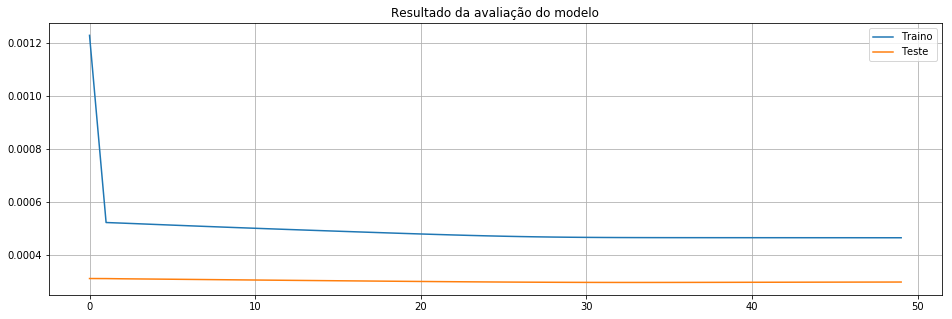

In [83]:
#CÉLULA TCC-80
plt.figure(figsize=(16,5))
plt.plot(h.history['loss'], label='Traino')
plt.plot(h.history['val_loss'], label='Teste')
plt.legend()
plt.title("Resultado da avaliação do modelo")
plt.grid()
plt.show()

In [84]:
#CÉLULA TCC-81
#Realizando uma predição
y_pred_Train = model.predict(X_train)
y_pred_Test = model.predict(X_test)

X_train = X_train.reshape((X_train.shape[0], X_train.shape[2]))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[2]))

# Invertendo a escala para previsão
inv_y_pred_Train = np.concatenate((y_pred_Train, X_train[:, 1:]), axis=1)#-6
inv_y_pred_Train = min_max_scaler.inverse_transform(inv_y_pred_Train)
inv_y_pred_Train = inv_y_pred_Train[:,0]

inv_y_pred_Test = np.concatenate((y_pred_Test, X_test[:, 1:]), axis=1)#-6
inv_y_pred_Test = min_max_scaler.inverse_transform(inv_y_pred_Test)
inv_y_pred_Test = inv_y_pred_Test[:,0]

# Invertendo a escala atual
y_train = y_train.reshape((len(y_train), 1))
inv_y_Train = np.concatenate((y_train, X_train[:, 1:]), axis=1)#-6
inv_y_Train = min_max_scaler.inverse_transform(inv_y_Train)
inv_y_Train = inv_y_Train[:,0]

y_test = y_test.reshape((len(y_test), 1))
inv_y_Test = np.concatenate((y_test, X_test[:, 1:]), axis=1)#-6
inv_y_Test = min_max_scaler.inverse_transform(inv_y_Test)
inv_y_Test = inv_y_Test[:,0]

In [85]:
#CÉLULA TCC-82
#Exibindo os resultados de treino e teste
print('------------------- TREINO -------------------------')
print('MSE: {:.6f}'.format(metrics.mean_squared_error(inv_y_Train, inv_y_pred_Train)))
print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(inv_y_Train, inv_y_pred_Train))))
print('r²: {:.2f} %'.format(r2_score(inv_y_Train, inv_y_pred_Train) * 100))
print('MAE: {:.6f}'.format(mean_absolute_error(inv_y_Train, inv_y_pred_Train)))
print('------------------- TESTE ---------------------------')
print('MSE: {:.6f}'.format(metrics.mean_squared_error(inv_y_Test, inv_y_pred_Test)))
print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(inv_y_Test, inv_y_pred_Test))))
print('r²: {:.2f} %'.format(r2_score(inv_y_Test, inv_y_pred_Test) * 100))
print('MAE: {:.6f}'.format(mean_absolute_error(inv_y_Test, inv_y_pred_Test)))

------------------- TREINO -------------------------
MSE: 40035.429688
RMSE: 200.088562
r²: 89.57 %
MAE: 85.662292
------------------- TESTE ---------------------------
MSE: 25655.484375
RMSE: 160.173294
r²: 89.89 %
MAE: 70.335999


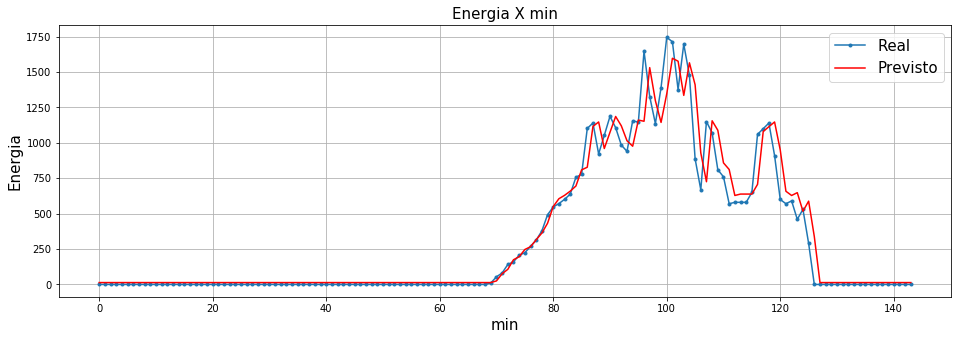

In [86]:
#CÉLULA TCC-83
#Exibindo um gráfico da previsão
qtdRegPred = len(inv_y_Test)
qtdRegPred = 144

dataPlot=[x for x in range(qtdRegPred)]
plt.figure(figsize=(16,5))
plt.plot(dataPlot, inv_y_Test[:qtdRegPred], marker='.', label="Real")
plt.plot(dataPlot, inv_y_pred_Test[:qtdRegPred], 'r', label="Previsto")
plt.ylabel('Energia', size=15)
plt.xlabel('min', size=15)
plt.legend(fontsize=15)
plt.title('Energia X min', size=15)
plt.grid()
plt.show()

## 4 - Conclusão

...

## 5 - Melhorias futuras

Acreditamos que com a obtenção de mais dados, completando assim mais de dois anos de dados, que o modelo de rede neural se comporte de uma maneira melhor, podendo prever corretamente os valores de geração de energia com mais facilidade e com um tempo a frente maior, não so dez min.

## Referências
Foram utilizados os seguintes links como referências:

- https://towardsdatascience.com/linear-regression-in-python-9a1f5f000606
- https://www.dataquest.io/blog/understanding-regression-error-metrics/
- https://machinelearningmastery.com/multivariate-time-series-forecasting-lstms-keras/